# 라벨 없는 GT 데이터 이상 탐지 및 시각화
Project_final_pt_20_23.pkl에 Neural ODE 기반 이상 탐지 모델 적용 후 publication-quality 시각화

**사용 전 준비**: `neuralode_model.py`가 research 폴더에 있어야 합니다. 이 파일은 `ADD_NeuralODE_Open_neuralode_3_3.ipynb`에서 추출한 모델 정의입니다. 별도로 다른 노트북을 실행할 필요 없이 이 노트북만 실행하면 됩니다.

In [1]:
# CSV data 폴더의 Project_final_pt_20_23.pkl 로드 및 형태 확인
import pickle as pk
import pandas as pd
from pathlib import Path

DATA_PATH = Path('CSV data') / 'Project_final_pt_20_23.pkl'

with open(DATA_PATH, 'rb') as f:
    _df_inspect = pk.load(f)

print("=== 데이터 형태 확인 ===")
print("Type:", type(_df_inspect))
if isinstance(_df_inspect, pd.DataFrame):
    print("Shape:", _df_inspect.shape)
    print("Columns:", _df_inspect.columns.tolist())
    print("Index type:", type(_df_inspect.index))
    print("Index name:", _df_inspect.index.name)
    if len(_df_inspect) > 0:
        print("Index sample:", list(_df_inspect.index[:3]))
    print("\nFirst 3 rows:")
    print(_df_inspect.head(3))
else:
    print("Data:", _df_inspect)

=== 데이터 형태 확인 ===
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (29256, 7)
Columns: ['b210_pt', 'b055_raw', 'b103_raw', 'b166_raw', 'b002_raw', 'b084_raw', 'b081_raw']
Index type: <class 'pandas.core.indexes.base.Index'>
Index name: Date/Time
Index sample: ['2020-01-01 00:00:00', '2020-01-01 01:00:00', '2020-01-01 02:00:00']

First 3 rows:
                     b210_pt  b055_raw  b103_raw  b166_raw  b002_raw  \
Date/Time                                                              
2020-01-01 00:00:00      NaN       NaN       NaN       NaN       NaN   
2020-01-01 01:00:00      NaN     37.25       0.5     82.25     18.00   
2020-01-01 02:00:00      NaN     32.50       0.5     92.25     15.75   

                     b084_raw  b081_raw  
Date/Time                                
2020-01-01 00:00:00       NaN       NaN  
2020-01-01 01:00:00     28.25       NaN  
2020-01-01 02:00:00     26.75       NaN  


In [2]:
import os
import sys
import pickle as pk
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.ndimage import gaussian_filter1d

# neuralode_model.py에서 모델 클래스 로드 (ADD_NeuralODE_Open_neuralode_3_3.ipynb와 동일)
from neuralode_model import RobustGradientSpikeDetector, init_model_weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("RobustGradientSpikeDetector 로드됨 (neuralode_model.py)")

RobustGradientSpikeDetector 로드됨 (neuralode_model.py)


In [3]:
def load_unlabeled_pkl(pkl_path, feature_cols=None, date_col='Date/Time',
                       fill_method='ffill', max_missing_ratio=0.5):
    """라벨 없는 PKL(DataFrame) 로드 및 전처리"""
    if isinstance(pkl_path, str) and not pkl_path.endswith('.pkl'):
        pkl_path = pkl_path + '.pkl'
    with open(pkl_path, 'rb') as f:
        df = pk.load(f)
    if not isinstance(df, pd.DataFrame):
        df = pd.DataFrame(df)
    if date_col not in df.columns:
        if hasattr(df.index, 'dtype') and str(df.index.dtype).startswith('datetime'):
            df = df.reset_index()
            idx_col = df.columns[0]
            df = df.rename(columns={idx_col: date_col})
        else:
            df[date_col] = pd.date_range('2020-01-01', periods=len(df), freq='H')
    df[date_col] = pd.to_datetime(df[date_col])
    return _preprocess_df(df, feature_cols, date_col, fill_method, max_missing_ratio)


def load_unlabeled_csv(csv_path, feature_cols=None, date_col='Date/Time', 
                       fill_method='ffill', max_missing_ratio=0.5):
    """라벨 없는 CSV 로드 및 전처리"""
    df = pd.read_csv(csv_path)
    df[date_col] = pd.to_datetime(df[date_col])
    return _preprocess_df(df, feature_cols, date_col, fill_method, max_missing_ratio)


def _preprocess_df(df, feature_cols, date_col, fill_method, max_missing_ratio):
    
    if feature_cols is None:
        exclude = [date_col, 'label', 'Label', 'timestamp']
        feature_cols = [c for c in df.columns if c not in exclude and df[c].dtype in [np.float64, np.int64, float, int]]
    else:
        feature_cols = [c for c in feature_cols if c in df.columns]
    if not feature_cols:
        raise ValueError("사용할 feature column이 없습니다.")
    X = df[feature_cols].copy()
    X = X.replace([np.inf, -np.inf], np.nan)
    
    for c in X.columns:
        missing = X[c].isna().mean()
        if missing > max_missing_ratio:
            X = X.drop(columns=[c])
            feature_cols = [f for f in feature_cols if f != c]
        else:
            if fill_method == 'ffill':
                X[c] = X[c].ffill().bfill()
            X[c] = X[c].fillna(X[c].mean())
    
    dates = df[date_col].values
    X = X.values.astype(np.float32)
    return X, dates, feature_cols


def load_unlabeled(data_path, feature_cols=None, **kwargs):
    """pkl 또는 csv 로드 (경로 확장자로 자동 판별)"""
    path = Path(data_path)
    if not path.exists() and 'CSV data' not in str(data_path):
        path = Path('CSV data') / path.name
    path = str(path)
    if path.endswith('.pkl'):
        return load_unlabeled_pkl(path, feature_cols=feature_cols, **kwargs)
    return load_unlabeled_csv(path, feature_cols=feature_cols, **kwargs)


def create_windows(data, window_size, stride=1):
    windows = []
    for i in range(0, len(data) - window_size + 1, stride):
        windows.append(data[i:i+window_size])
    return np.array(windows)


def load_and_prepare_unlabeled(data_path, window_size=50, stride=1, train_ratio=0.7, 
                               feature_cols=None, normalize=True):
    """라벨 없는 데이터(pkl/csv) 로드, 윈도우 생성, train/test 분리"""
    X, dates, feature_cols = load_unlabeled(data_path, feature_cols=feature_cols)
    
    if normalize:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
    else:
        scaler = None
    
    windows = create_windows(X, window_size, stride)
    n = len(windows)
    split = int(n * train_ratio)
    train_windows = windows[:split]
    test_windows = windows[split:]
    
    dates_windows = dates[window_size-1::stride][:n]
    test_dates = dates_windows[split:]
    
    return {
        'x_trn': torch.FloatTensor(train_windows),
        'x_tst': torch.FloatTensor(test_windows),
        'scaler': scaler,
        'dates': dates,
        'test_dates': test_dates,
        'input_dim': X.shape[1],
        'window_size': window_size,
        'stride': stride,
    }

In [4]:
def train_model_unlabeled(model, data_dict, num_epochs=30, batch_size=64, device=None):
    """라벨 없는 데이터로 비지도 학습"""
    if device is None:
        device = next(model.parameters()).device
    model = model.to(device)
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    
    x_trn = data_dict['x_trn']
    seq_len = x_trn.shape[1]
    time_steps = torch.linspace(0, 1, seq_len).unsqueeze(0).repeat(x_trn.shape[0], 1).to(device)
    dataset = TensorDataset(x_trn, time_steps)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    
    for epoch in range(num_epochs):
        total_loss = 0
        for batch_x, batch_t in loader:
            batch_x = batch_x.to(device)
            batch_t = batch_t.to(device)
            out = model(batch_x, batch_t)
            loss = out['losses']['total_loss']
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs} Loss: {total_loss/len(loader):.6f}")
    return model

In [5]:
def extract_window_components(model, window_tensor, device):
    """단일 윈도우에 대해 anomaly score와 components 추출"""
    model.eval()
    window_tensor = window_tensor.to(device)
    seq_len = window_tensor.shape[1]
    time_steps = torch.linspace(0, 1, seq_len, device=device).unsqueeze(0)
    unique_times = torch.linspace(0, 1, seq_len, device=device)
    
    with torch.no_grad():
        z_latent, mu, logvar = model.encoder(window_tensor, time_steps)
        if model.noise_enabled:
            z_noise = model.noise_projector(z_latent)
            z0 = z_latent - z_noise
            noise_init = z_noise
            initial_state = (z0, torch.zeros(z0.size(0), device=device), noise_init)
        else:
            z0 = z_latent
            noise_init = None
            initial_state = (z0, torch.zeros(z0.size(0), device=device))
        
        integration_result = model._ode_integrate(initial_state, unique_times)
        if model.noise_enabled:
            z_traj, d_traj, n_traj = integration_result
        else:
            z_traj, d_traj = integration_result
            n_traj = None
        
        score, components = model._compute_score(
            window_tensor, z_traj, d_traj, unique_times, mu, logvar,
            is_forward=True, noise_trajectory=n_traj, return_components=True
        )
    
    def to_np(x):
        if x is None: return None
        v = x.cpu().numpy() if isinstance(x, torch.Tensor) else np.asarray(x)
        return np.squeeze(v)
    
    score_val = float(to_np(score).reshape(-1)[0])
    comp_np = {k: to_np(v) for k, v in components.items()}
    return score_val, comp_np


def compute_scores_and_components(model, x_windows, device, batch_size=64):
    """전체 윈도우에 대해 score, recon, drift, grad 시계열 생성"""
    model.eval()
    scores_list, recon_list, drift_list, grad_list = [], [], [], []
    
    for i in range(0, len(x_windows), batch_size):
        batch = x_windows[i:i+batch_size]
        if isinstance(batch, np.ndarray):
            batch = torch.FloatTensor(batch).to(device)
        else:
            batch = batch.to(device)
        
        for j in range(batch.shape[0]):
            w = batch[j:j+1]
            sc, comp = extract_window_components(model, w, device)
            scores_list.append(sc)
            r = comp.get('recon_time')
            recon_list.append(np.mean(r) if r is not None and r.size > 0 else 0)
            d = comp.get('drift')
            drift_list.append(float(d) if d is not None else 0)
            g = comp.get('grad_energy')
            grad_list.append(np.mean(g) if g is not None and g.size > 0 else 0)
    
    recon_arr = np.array(recon_list)
    drift_arr = np.array(drift_list)
    grad_arr = np.array(grad_list)
    scores_arr = np.array(scores_list)
    
    recon_smooth = gaussian_filter1d(recon_arr, sigma=2)
    drift_smooth = gaussian_filter1d(drift_arr, sigma=2)
    grad_smooth = gaussian_filter1d(grad_arr, sigma=2)
    
    return scores_arr, recon_smooth, drift_smooth, grad_smooth

In [6]:
# CSV data 폴더 (research 기준 상대경로)
DATA_PATH = Path('CSV data') / 'Project_final_pt_20_23.pkl'
# pkl 컬럼: b210_pt, b055_raw, b103_raw, b166_raw, b002_raw, b084_raw, b081_raw
FEATURE_COLS = ['b055_raw', 'b103_raw', 'b166_raw', 'b002_raw']

data_dict = load_and_prepare_unlabeled(
    DATA_PATH,
    window_size=50,
    stride=1,
    train_ratio=0.7,
    feature_cols=FEATURE_COLS,
)

input_dim = data_dict['input_dim']
print(f"입력 차원: {input_dim}, 훈련 윈도우: {data_dict['x_trn'].shape[0]}, 테스트 윈도우: {data_dict['x_tst'].shape[0]}")

입력 차원: 4, 훈련 윈도우: 20444, 테스트 윈도우: 8763


In [7]:
model = RobustGradientSpikeDetector(
    input_dim=input_dim,
    latent_dim=32,
    hidden_dim=64,
    time_emb_dim=8,
    beta=0.05,
    noise_enabled=False,
).to(device)

init_model_weights(model)

model = train_model_unlabeled(
    model, data_dict, num_epochs=250, batch_size=128, device=device
)

Epoch 10/250 Loss: 0.696415
Epoch 20/250 Loss: 0.696182
Epoch 30/250 Loss: 0.697011
Epoch 40/250 Loss: 0.701285
Epoch 50/250 Loss: 0.696774
Epoch 60/250 Loss: 0.695994
Epoch 70/250 Loss: 0.695919
Epoch 80/250 Loss: 0.696315
Epoch 90/250 Loss: 0.696402
Epoch 100/250 Loss: 0.696322
Epoch 110/250 Loss: 0.699759
Epoch 120/250 Loss: 0.697066
Epoch 130/250 Loss: 0.695918
Epoch 140/250 Loss: 0.696741
Epoch 150/250 Loss: 0.696650
Epoch 160/250 Loss: 0.696654
Epoch 170/250 Loss: 0.696438
Epoch 180/250 Loss: 0.696712
Epoch 190/250 Loss: 0.696198
Epoch 200/250 Loss: 0.695926
Epoch 210/250 Loss: 0.696321
Epoch 220/250 Loss: 0.696816
Epoch 230/250 Loss: 0.696488
Epoch 240/250 Loss: 0.697572
Epoch 250/250 Loss: 0.696451


In [11]:
x_tst = data_dict['x_tst'].numpy()
scores_arr, recon_smooth, drift_smooth, grad_smooth = compute_scores_and_components(
    model, x_tst, device, batch_size=128
)

total_score = recon_smooth + drift_smooth + grad_smooth
threshold = np.percentile(total_score, 95)
detected_anomalies = total_score > threshold

dates = data_dict['test_dates']
print(f"점수 길이: {len(scores_arr)}, 날짜 길이: {len(dates)}")
print(f"Threshold (95%): {threshold:.4f}, 탐지된 이상 구간: {np.sum(detected_anomalies)}개")

# 실험 결과 피클로 저장
RESULTS_PATH = Path('CSV data') / 'GT_unlabeled_experiment_results.pkl'
Path('CSV data').mkdir(parents=True, exist_ok=True)
with open(RESULTS_PATH, 'wb') as f:
    pk.dump({
        'scores_arr': scores_arr,
        'recon_smooth': recon_smooth,
        'drift_smooth': drift_smooth,
        'grad_smooth': grad_smooth,
        'total_score': total_score,
        'threshold': threshold,
        'detected_anomalies': detected_anomalies,
        'dates': dates,
        'FEATURE_COLS': FEATURE_COLS,
        'model_state_dict': model.state_dict(),
        'data_dict_keys': list(data_dict.keys()),
    }, f, protocol=pk.HIGHEST_PROTOCOL)
print(f"실험 결과 저장: {RESULTS_PATH}")

점수 길이: 8763, 날짜 길이: 8763
Threshold (95%): 0.0000, 탐지된 이상 구간: 439개
실험 결과 저장: CSV data\GT_unlabeled_experiment_results.pkl


In [12]:
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['grid.alpha'] = 0.3

COLORS = {
    'primary': '#2E5266',
    'recon': '#D62828',
    'drift': '#F77F00',
    'spike': '#06A77D',
    'anomaly': '#D62828',
    'threshold': '#333333',
    'sensor1': '#2E5266', 'sensor2': '#6A994E', 'sensor3': '#BC4749', 'sensor4': '#F2A900',
    'background': '#F8F9FA', 'grid': '#CCCCCC'
}

C:\Users\keun\AppData\Local\Temp\ipykernel_11312\3040727903.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


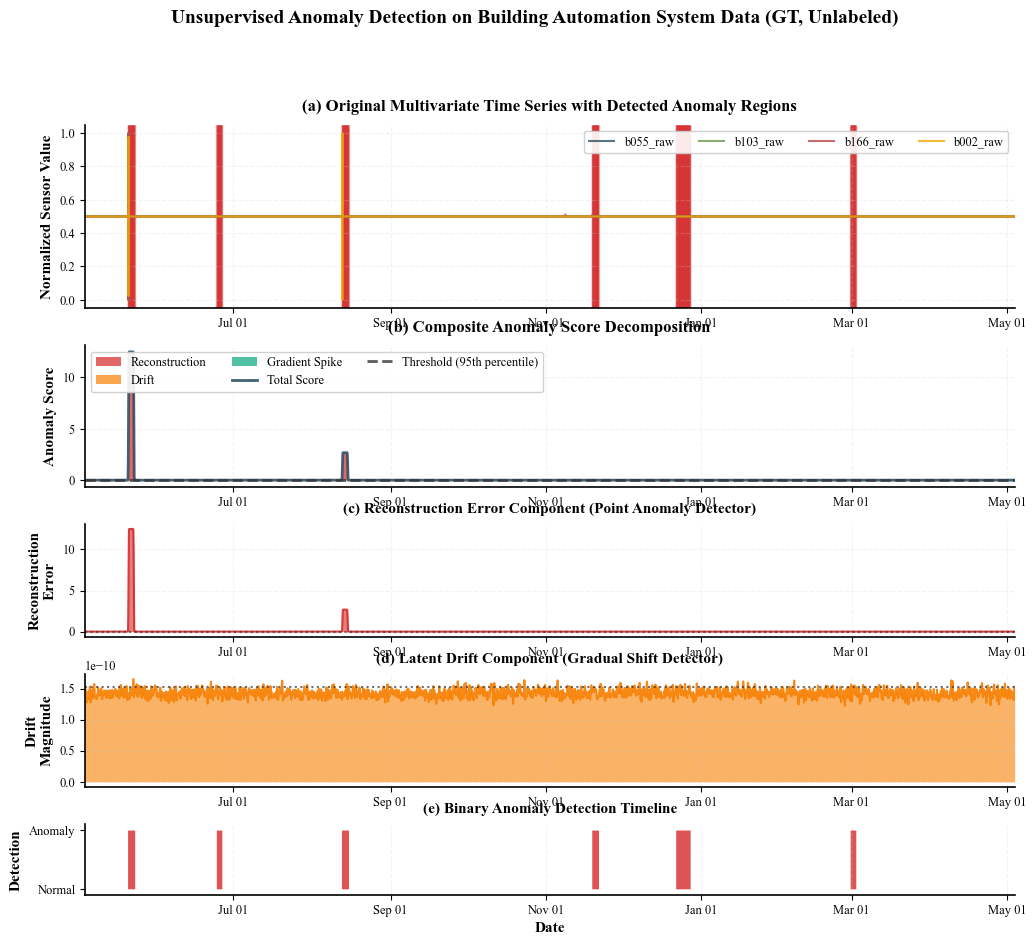

저장: figs/GT_unlabeled_publication_results.png, .pdf


In [13]:
fig = plt.figure(figsize=(12, 10), facecolor='white')
gs = fig.add_gridspec(5, 1, height_ratios=[1.3, 1.0, 0.8, 0.8, 0.5], hspace=0.3)

# 원본 시계열 (대표 변수 4개)
ax1 = fig.add_subplot(gs[0])
ax1.set_facecolor('white')

with open(DATA_PATH, 'rb') as f:
    df_raw = pk.load(f)
if not isinstance(df_raw, pd.DataFrame):
    df_raw = pd.DataFrame(df_raw)
# Date/Time이 컬럼에 없으면 인덱스에서 컬럼으로 올리기 (인덱스가 datetime이거나 인덱스 이름이 'Date/Time'인 경우)
if 'Date/Time' not in df_raw.columns:
    index_is_datetime = hasattr(df_raw.index, 'dtype') and str(df_raw.index.dtype).startswith('datetime')
    index_named_datetime = getattr(df_raw.index, 'name', None) == 'Date/Time'
    if index_is_datetime or index_named_datetime:
        df_raw = df_raw.reset_index()
        if df_raw.columns[0] != 'Date/Time':
            df_raw = df_raw.rename(columns={df_raw.columns[0]: 'Date/Time'})
df_raw['Date/Time'] = pd.to_datetime(df_raw['Date/Time'])
dt0, dt1 = pd.Timestamp(dates[0]), pd.Timestamp(dates[-1])
df_plot = df_raw[(df_raw['Date/Time'] >= dt0) & (df_raw['Date/Time'] <= dt1)].reset_index(drop=True)
dates_plot = df_plot['Date/Time'].values

for i, var in enumerate(FEATURE_COLS):
    if var in df_plot.columns:
        vals = df_plot[var].values.astype(float)
        valid = ~np.isnan(vals)
        vals[~valid] = np.nanmedian(vals[valid]) if np.any(valid) else 0
        mn, mx = np.nanmin(vals), np.nanmax(vals)
        norm = (vals - mn) / (mx - mn + 1e-8)
        ax1.plot(dates_plot, norm, label=var, color=COLORS[f'sensor{i+1}'], alpha=0.8, linewidth=1.5)

for i in range(len(detected_anomalies)):
    if detected_anomalies[i] and i < len(dates):
        d0 = pd.Timestamp(dates[i])
        d1 = pd.Timestamp(dates[min(i+1, len(dates)-1)]) if i+1 < len(dates) else d0
        ax1.axvspan(d0, d1, alpha=0.15, color=COLORS['anomaly'], zorder=1)

ax1.set_ylabel('Normalized Sensor Value', fontweight='bold')
ax1.set_title('(a) Original Multivariate Time Series with Detected Anomaly Regions', fontweight='bold', pad=10)
ax1.legend(loc='upper right', frameon=True, ncol=4, framealpha=0.9)
ax1.grid(True, alpha=0.25, linestyle='--', color=COLORS['grid'])
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.set_xlim(dates[0], dates[-1])

# Composite Anomaly Score Decomposition
ax2 = fig.add_subplot(gs[1])
ax2.set_facecolor('white')

ax2.fill_between(dates, 0, recon_smooth, alpha=0.7, color=COLORS['recon'], label='Reconstruction', linewidth=0)
ax2.fill_between(dates, recon_smooth, recon_smooth + drift_smooth, alpha=0.7, color=COLORS['drift'], label='Drift', linewidth=0)
ax2.fill_between(dates, recon_smooth + drift_smooth, total_score, alpha=0.7, color=COLORS['spike'], label='Gradient Spike', linewidth=0)
ax2.plot(dates, total_score, color=COLORS['primary'], linewidth=2, alpha=0.9, label='Total Score')
ax2.axhline(threshold, color=COLORS['threshold'], linestyle='--', linewidth=2, label='Threshold (95th percentile)', alpha=0.8)

ax2.set_ylabel('Anomaly Score', fontweight='bold')
ax2.set_title('(b) Composite Anomaly Score Decomposition', fontweight='bold', pad=10)
ax2.legend(loc='upper left', frameon=True, ncol=3, framealpha=0.9)
ax2.grid(True, alpha=0.25, linestyle='--', color=COLORS['grid'])
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xlim(dates[0], dates[-1])

# Reconstruction Component
ax3 = fig.add_subplot(gs[2])
ax3.set_facecolor('white')
ax3.fill_between(dates, 0, recon_smooth, alpha=0.6, color=COLORS['recon'], linewidth=0)
ax3.plot(dates, recon_smooth, color=COLORS['recon'], linewidth=1.5, alpha=0.9)
ax3.axhline(np.percentile(recon_smooth, 95), color=COLORS['threshold'], linestyle=':', linewidth=1.5, alpha=0.7)
ax3.set_ylabel('Reconstruction\nError', fontweight='bold')
ax3.set_title('(c) Reconstruction Error Component (Point Anomaly Detector)', fontweight='bold', pad=8, fontsize=11)
ax3.grid(True, alpha=0.25, linestyle='--', color=COLORS['grid'])
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.set_xlim(dates[0], dates[-1])

# Drift Component
ax4 = fig.add_subplot(gs[3])
ax4.set_facecolor('white')
ax4.fill_between(dates, 0, drift_smooth, alpha=0.6, color=COLORS['drift'], linewidth=0)
ax4.plot(dates, drift_smooth, color=COLORS['drift'], linewidth=1.5, alpha=0.9)
ax4.axhline(np.percentile(drift_smooth, 95), color=COLORS['threshold'], linestyle=':', linewidth=1.5, alpha=0.7)
ax4.set_ylabel('Drift\nMagnitude', fontweight='bold')
ax4.set_title('(d) Latent Drift Component (Gradual Shift Detector)', fontweight='bold', pad=8, fontsize=11)
ax4.grid(True, alpha=0.25, linestyle='--', color=COLORS['grid'])
ax4.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.set_xlim(dates[0], dates[-1])

# Binary Detection
ax5 = fig.add_subplot(gs[4])
ax5.set_facecolor('white')
ax5.fill_between(dates, 0, detected_anomalies.astype(float), alpha=0.8, color=COLORS['anomaly'], step='mid', linewidth=0)
ax5.set_ylabel('Detection', fontweight='bold')
ax5.set_xlabel('Date', fontweight='bold')
ax5.set_title('(e) Binary Anomaly Detection Timeline', fontweight='bold', pad=8, fontsize=11)
ax5.set_yticks([0, 1])
ax5.set_yticklabels(['Normal', 'Anomaly'])
ax5.grid(True, alpha=0.25, linestyle='--', color=COLORS['grid'], axis='x')
ax5.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)
ax5.set_xlim(dates[0], dates[-1])
ax5.set_ylim(-0.1, 1.1)

plt.suptitle('Unsupervised Anomaly Detection on Building Automation System Data (GT, Unlabeled)', 
             fontweight='bold', fontsize=14, y=0.995)
plt.tight_layout()

save_dir = Path('figs')
save_dir.mkdir(exist_ok=True)
fig.savefig(save_dir / 'GT_unlabeled_publication_results.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(save_dir / 'GT_unlabeled_publication_results.pdf', bbox_inches='tight', facecolor='white')
plt.show()
print('저장: figs/GT_unlabeled_publication_results.png, .pdf')

In [ ]:
``